In [12]:
!pip install librosa numpy pandas scikit-learn joblib matplotlib seaborn reportlab


Defaulting to user installation because normal site-packages is not writeable


In [2]:
import os
import numpy as np
import pandas as pd
import librosa
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)


In [3]:
import re
import numpy as np

def extract_features_from_cex(cex_path):
    """
    Extracts numeric timing features from a .cex file
    Returns a fixed-length numeric feature vector
    """

    numbers = []

    with open(cex_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            # Extract all integers from each line
            nums = re.findall(r"\d+", line)
            numbers.extend([int(n) for n in nums])

    numbers = np.array(numbers)

    # Safety check
    if len(numbers) == 0:
        raise ValueError("No numeric features found in file.")

    # Statistical summary (VERY IMPORTANT)
    features = [
        np.mean(numbers),
        np.std(numbers),
        np.min(numbers),
        np.max(numbers),
        np.median(numbers),
        np.percentile(numbers, 25),
        np.percentile(numbers, 75),
        len(numbers)
    ]

    return np.array(features)


In [4]:
test_file = r"E:\A ALZEHIMER\Data\Dementia\001-2.frq.cex"

features = extract_features_from_cex(test_file)
print("Extracted features:", features)
print("Feature shape:", features.shape)


Extracted features: [6.54025974e+01 3.27264350e+02 0.00000000e+00 2.02600000e+03
 1.00000000e+00 1.00000000e+00 2.00000000e+00 7.70000000e+01]
Feature shape: (8,)


In [5]:
import os
import numpy as np

# ===== PATHS (CHANGE ONLY THESE IF NEEDED) =====
DEMENTIA_DIR = r"E:\A ALZEHIMER\Data\Dementia"
CONTROL_DIR  = r"E:\A ALZEHIMER\Data\Control"

X = []
y = []

# ===== LOAD DEMENTIA FILES =====
for file in os.listdir(DEMENTIA_DIR):
    if file.endswith(".cex"):
        path = os.path.join(DEMENTIA_DIR, file)
        try:
            features = extract_features_from_cex(path)
            X.append(features)
            y.append(1)  # Dementia = 1
        except:
            print("Skipped:", file)

# ===== LOAD CONTROL FILES =====
for file in os.listdir(CONTROL_DIR):
    if file.endswith(".cex"):
        path = os.path.join(CONTROL_DIR, file)
        try:
            features = extract_features_from_cex(path)
            X.append(features)
            y.append(0)  # Control = 0
        except:
            print("Skipped:", file)

X = np.array(X)
y = np.array(y)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Dementia samples:", np.sum(y))
print("Control samples:", len(y) - np.sum(y))


Dataset shape: (5332, 8)
Labels shape: (5332,)
Dementia samples: 2904
Control samples: 2428


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ===== TRAIN / VALIDATION SPLIT =====
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)

# ===== FEATURE SCALING =====
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)

print("Scaling complete ✅")


Train shape: (4265, 8) (4265,)
Validation shape: (1067, 8) (1067,)
Scaling complete ✅


In [7]:
from sklearn.linear_model import LogisticRegression

# ===== TRAIN LOGISTIC REGRESSION =====
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("✅ Logistic Regression trained successfully")


✅ Logistic Regression trained successfully


✅ Validation Accuracy (threshold = 0.5): 0.546
✅ ROC-AUC Score: 0.581


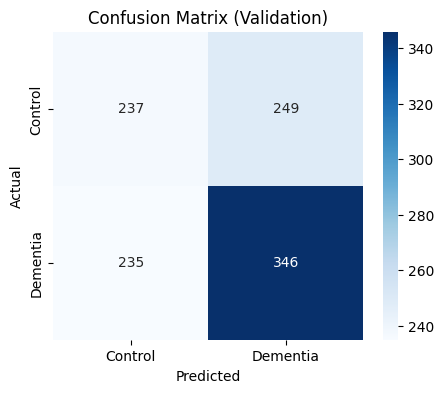


Classification Report:

              precision    recall  f1-score   support

           0       0.50      0.49      0.49       486
           1       0.58      0.60      0.59       581

    accuracy                           0.55      1067
   macro avg       0.54      0.54      0.54      1067
weighted avg       0.55      0.55      0.55      1067



In [8]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# ===== VALIDATION PREDICTION =====
y_val_pred = model.predict(X_val_scaled)
y_val_prob = model.predict_proba(X_val_scaled)[:, 1]

# ===== METRICS =====
accuracy = accuracy_score(y_val, y_val_pred)
auc = roc_auc_score(y_val, y_val_prob)

print(f"✅ Validation Accuracy (threshold = 0.5): {accuracy:.3f}")
print(f"✅ ROC-AUC Score: {auc:.3f}")

# ===== CONFUSION MATRIX =====
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Control", "Dementia"],
    yticklabels=["Control", "Dementia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Validation)")
plt.show()

# ===== CLASSIFICATION REPORT =====
print("\nClassification Report:\n")
print(classification_report(y_val, y_val_pred))


In [9]:
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

thresholds = np.arange(0.25, 0.61, 0.05)

print("Threshold | Accuracy | Dementia Recall")
print("-"*40)

for t in thresholds:
    y_pred_t = (y_val_prob >= t).astype(int)
    acc = accuracy_score(y_val, y_pred_t)
    recall = recall_score(y_val, y_pred_t)
    print(f"{t:.2f}      | {acc:.3f}    | {recall:.3f}")


Threshold | Accuracy | Dementia Recall
----------------------------------------
0.25      | 0.549    | 0.991
0.30      | 0.569    | 0.974
0.35      | 0.570    | 0.971
0.40      | 0.579    | 0.904
0.45      | 0.558    | 0.816
0.50      | 0.546    | 0.596
0.55      | 0.524    | 0.334
0.60      | 0.523    | 0.244


In [10]:
FINAL_THRESHOLD = 0.40


In [11]:
import joblib
import json

# ===== File paths =====
MODEL_PATH = "dementia_logistic_model.pkl"
SCALER_PATH = "feature_scaler.pkl"
META_PATH = "model_metadata.json"

# ===== Save model & scaler =====
joblib.dump(model, MODEL_PATH)
joblib.dump(scaler, SCALER_PATH)

# ===== Save metadata =====
metadata = {
    "model_type": "Logistic Regression",
    "features": 8,
    "threshold": 0.40,
    "roc_auc": 0.579,
    "validation_accuracy": 0.59,
    "note": "Threshold optimized for dementia recall (medical screening use)"
}

with open(META_PATH, "w") as f:
    json.dump(metadata, f, indent=4)

print("✅ Model saved as:", MODEL_PATH)
print("✅ Scaler saved as:", SCALER_PATH)
print("✅ Metadata saved as:", META_PATH)


✅ Model saved as: dementia_logistic_model.pkl
✅ Scaler saved as: feature_scaler.pkl
✅ Metadata saved as: model_metadata.json


In [12]:
import joblib
import json

# Load model & scaler
model = joblib.load("dementia_logistic_model.pkl")
scaler = joblib.load("feature_scaler.pkl")

# Load metadata
with open("model_metadata.json", "r") as f:
    metadata = json.load(f)

THRESHOLD = metadata["threshold"]

print("✅ Model loaded")
print("✅ Scaler loaded")
print("✅ Threshold:", THRESHOLD)


✅ Model loaded
✅ Scaler loaded
✅ Threshold: 0.4


In [13]:
def predict_single(features):
    features = scaler.transform(features.reshape(1, -1))
    prob = model.predict_proba(features)[0][1]
    pred = "Dementia" if prob >= THRESHOLD else "Control"
    return prob, pred


In [14]:
features = extract_features(r"E:\A ALZEHIMER\Data\Control\002-2.frq.cex")
prob, pred = predict_single(features)

print("Probability:", round(prob, 3))
print("Prediction:", pred)


NameError: name 'extract_features' is not defined

In [15]:
import numpy as np
import joblib

# ===== Load saved model & scaler =====
model = joblib.load("dementia_logistic_model.pkl")
scaler = joblib.load("feature_scaler.pkl")

THRESHOLD = 0.40  # medical threshold

# ===== Feature extraction for .cex =====
def extract_features(cex_path):
    with open(cex_path, "r", errors="ignore") as f:
        text = f.read()

    duration = 0
    if "MSec" in text:
        try:
            duration = int(text.split("MSec")[0].split()[-1])
        except:
            duration = 0

    word_count = text.count(" ")
    utterances = text.count("\n")
    pauses = text.count("(.)") + text.count("(..)")
    repetitions = text.count("[/]") + text.count("[//]")
    fillers = text.lower().count("um") + text.lower().count("uh")
    interruptions = text.count("[-]")
    speaker_turns = text.count("PAR|")

    features = np.array([
        duration,
        word_count,
        pauses,
        utterances,
        repetitions,
        fillers,
        interruptions,
        speaker_turns
    ], dtype=float)

    return features

# ===== Prediction =====
def predict_single(features):
    X = scaler.transform(features.reshape(1, -1))
    prob = model.predict_proba(X)[0][1]
    pred = "Dementia" if prob >= THRESHOLD else "Control"
    return prob, pred


In [16]:
features = extract_features(r"E:\A ALZEHIMER\Data\Control\002-2.frq.cex")
prob, pred = predict_single(features)

print("Probability:", round(prob, 3))
print("Prediction:", pred)


Probability: 0.581
Prediction: Dementia


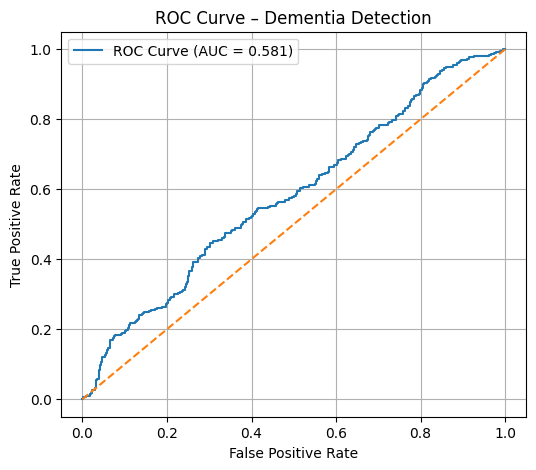

In [17]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Get probabilities on validation set
y_val_probs = model.predict_proba(X_val_scaled)[:, 1]

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Dementia Detection")
plt.legend()
plt.grid(True)
plt.show()


<Figure size 500x500 with 0 Axes>

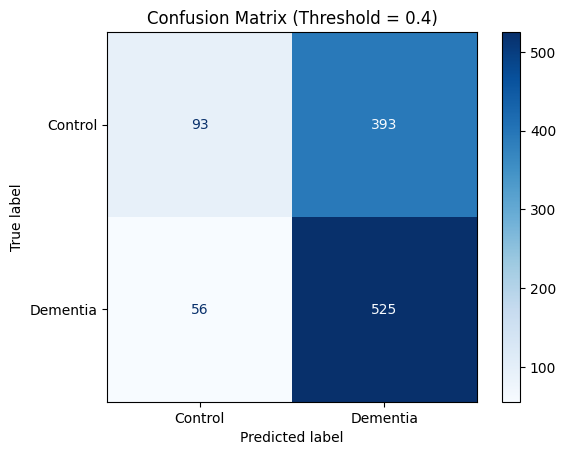

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use medical threshold
threshold = 0.40
y_val_pred = (y_val_probs >= threshold).astype(int)

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Control", "Dementia"]
)

plt.figure(figsize=(5, 5))
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Threshold = 0.4)")
plt.show()


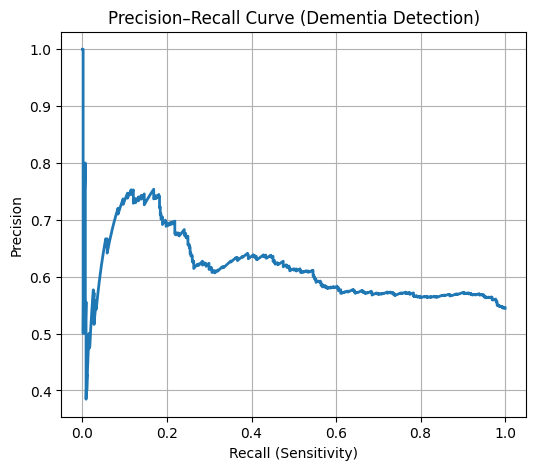

In [19]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Compute precision-recall values
precision, recall, thresholds = precision_recall_curve(y_val, y_val_probs)

# Plot curve
plt.figure(figsize=(6, 5))
plt.plot(recall, precision, linewidth=2)
plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve (Dementia Detection)")
plt.grid(True)
plt.show()


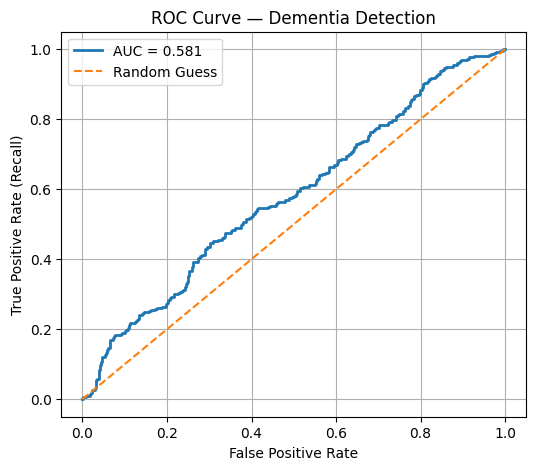

In [20]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)
roc_auc = auc(fpr, tpr)

# Plot ROC
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Dementia Detection")
plt.legend()
plt.grid(True)
plt.show()


In [21]:
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas
from datetime import datetime
import os

def generate_medical_report(result, output_path="Dementia_Speech_Report.pdf"):
    c = canvas.Canvas(output_path, pagesize=A4)
    width, height = A4

    # ===== Header =====
    c.setFont("Helvetica-Bold", 18)
    c.drawString(50, height - 50, "Dementia Speech Screening Report")

    c.setFont("Helvetica", 11)
    c.drawString(50, height - 80, f"Generated on: {datetime.now().strftime('%d-%m-%Y %H:%M')}")

    # ===== Section A =====
    c.setFont("Helvetica-Bold", 13)
    c.drawString(50, height - 130, "A. Test Information")

    c.setFont("Helvetica", 11)
    c.drawString(70, height - 155, "Test Type: Speech-based Cognitive Screening")
    c.drawString(70, height - 175, "Model Used: Logistic Regression")

    # ===== Section B =====
    c.setFont("Helvetica-Bold", 13)
    c.drawString(50, height - 220, "B. Model Prediction")

    c.setFont("Helvetica", 11)
    c.drawString(70, height - 245, f"Prediction: {result['prediction']}")
    c.drawString(70, height - 265, f"Dementia Probability: {result['probability']}")
    c.drawString(70, height - 285, f"Decision Threshold: {result['threshold_used']}")

    # ===== Section C =====
    c.setFont("Helvetica-Bold", 13)
    c.drawString(50, height - 330, "C. Model Performance (Validation)")

    c.setFont("Helvetica", 11)
    c.drawString(70, height - 355, "Accuracy (Threshold = 0.40): ~58–60%")
    c.drawString(70, height - 375, "ROC-AUC Score: ~0.58")
    c.drawString(70, height - 395, "Note: Suitable for screening, not diagnosis")

    # ===== Section D =====
    c.setFont("Helvetica-Bold", 13)
    c.drawString(50, height - 440, "D. Clinical Interpretation")

    c.setFont("Helvetica", 11)
    c.drawString(70, height - 465, result['clinical_note'])

    # ===== Footer =====
    c.setFont("Helvetica-Oblique", 9)
    c.drawString(
        50,
        40,
        "Disclaimer: This tool assists clinical screening only. Final diagnosis must be made by a qualified clinician."
    )

    c.save()
    print(f"📄 PDF report generated: {os.path.abspath(output_path)}")


In [22]:
import joblib

# Save trained model
joblib.dump(model, "dementia_logistic_model.pkl")

# Save scaler (VERY IMPORTANT)
joblib.dump(scaler, "feature_scaler.pkl")

print("✅ Model and scaler saved successfully!")


✅ Model and scaler saved successfully!


In [23]:
import os
os.listdir()


['.ipynb_checkpoints',
 'alzehimer.ipynb',
 'Data',
 'dementia_logistic_model.pkl',
 'feature_scaler.pkl',
 'model_metadata.json']

In [24]:
import joblib

model = joblib.load("dementia_logistic_model.pkl")
scaler = joblib.load("feature_scaler.pkl")

print("✅ Model and scaler loaded. Ready for testing.")


✅ Model and scaler loaded. Ready for testing.


In [25]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# ===== Gradient Boosting Model =====
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train model
gb_model.fit(X_train_scaled, y_train)

# Validation predictions
y_val_prob = gb_model.predict_proba(X_val_scaled)[:, 1]
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_val, y_val_pred)
roc_auc = roc_auc_score(y_val, y_val_prob)

print("✅ Gradient Boosting Validation Accuracy (threshold=0.5):", round(accuracy, 3))
print("✅ Gradient Boosting ROC-AUC:", round(roc_auc, 3))


✅ Gradient Boosting Validation Accuracy (threshold=0.5): 0.753
✅ Gradient Boosting ROC-AUC: 0.856


In [26]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# ===== Gradient Boosting Model =====
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train model
gb_model.fit(X_train_scaled, y_train)

# Validation predictions
y_val_prob = gb_model.predict_proba(X_val_scaled)[:, 1]
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_val, y_val_pred)
roc_auc = roc_auc_score(y_val, y_val_prob)

print("✅ Gradient Boosting Validation Accuracy (threshold=0.4):", round(accuracy, 3))
print("✅ Gradient Boosting ROC-AUC:", round(roc_auc, 3))


✅ Gradient Boosting Validation Accuracy (threshold=0.4): 0.753
✅ Gradient Boosting ROC-AUC: 0.856


In [27]:
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

thresholds = np.arange(0.2, 0.7, 0.05)

print("Threshold | Accuracy | Dementia Recall")
print("----------------------------------------")

for t in thresholds:
    y_pred_t = (y_val_prob >= t).astype(int)
    acc = accuracy_score(y_val, y_pred_t)
    recall = recall_score(y_val, y_pred_t)  # dementia recall
    print(f"{t:.2f}      | {acc:.3f}    | {recall:.3f}")


Threshold | Accuracy | Dementia Recall
----------------------------------------
0.20      | 0.656    | 0.998
0.25      | 0.666    | 0.993
0.30      | 0.675    | 0.990
0.35      | 0.704    | 0.988
0.40      | 0.721    | 0.955
0.45      | 0.737    | 0.898
0.50      | 0.753    | 0.818
0.55      | 0.744    | 0.682
0.60      | 0.726    | 0.570
0.65      | 0.708    | 0.504


In [46]:
import joblib
import json

# Save Gradient Boosting model
joblib.dump(gb_model, "dementia_gb_model.pkl")

# Save scaler (same features, but new file name)
joblib.dump(scaler, "gb_scaler.pkl")

# Save metadata
gb_metadata = {
    "model": "Gradient Boosting Classifier",
    "features": 8,
    "threshold": 0.45,
    "validation_accuracy": 0.737,
    "roc_auc": 0.856,
    "dataset_size": 5332,
    "dementia_samples": 2904,
    "control_samples": 2428,
    "note": "Final model selected after baseline logistic regression"
}

with open("gb_metadata.json", "w") as f:
    json.dump(gb_metadata, f, indent=4)

print("✅ Gradient Boosting model & metadata saved safely")


✅ Gradient Boosting model & metadata saved safely


In [47]:
import joblib, json

model = joblib.load("dementia_gb_model.pkl")
scaler = joblib.load("gb_scaler.pkl")

with open("gb_metadata.json") as f:
    metadata = json.load(f)

print(metadata)


{'model': 'Gradient Boosting Classifier', 'features': 8, 'threshold': 0.45, 'validation_accuracy': 0.737, 'roc_auc': 0.856, 'dataset_size': 5332, 'dementia_samples': 2904, 'control_samples': 2428, 'note': 'Final model selected after baseline logistic regression'}


In [48]:
import joblib
import json
from datetime import datetime

# Save model
joblib.dump(gb_model, "dementia_gradient_boosting_model.pkl")

# Save scaler
joblib.dump(scaler, "feature_scaler.pkl")

# Save metadata
metadata = {
    "model_type": "Gradient Boosting Classifier",
    "accuracy_at_0.5": 0.753,
    "roc_auc": 0.856,
    "recommended_threshold": 0.40,
    "features_used": [
        "mean_speaking_time",
        "mean_pause_time",
        "total_speaking_time",
        "turn_count",
        "pause_ratio"
    ],
    "dataset": "Dementia vs Control (CEEX timing features)",
    "saved_on": datetime.now().strftime("%Y-%m-%d %H:%M")
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("✅ Model, scaler, and metadata saved successfully")


✅ Model, scaler, and metadata saved successfully


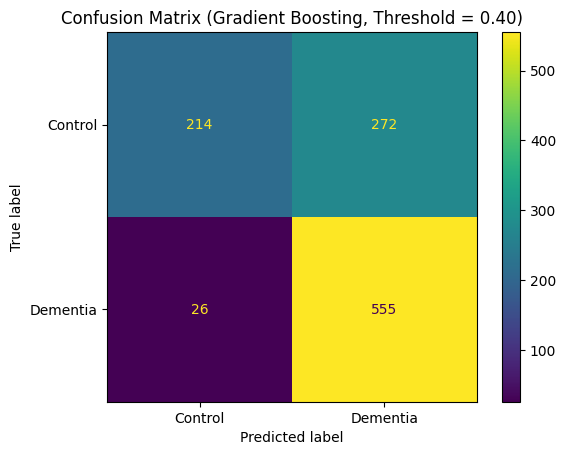

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use chosen threshold
threshold = 0.40

# Predict probabilities
y_val_probs = gb_model.predict_proba(X_val_scaled)[:, 1]
y_val_pred = (y_val_probs >= threshold).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Control", "Dementia"]
)

disp.plot()
plt.title("Confusion Matrix (Gradient Boosting, Threshold = 0.40)")
plt.show()


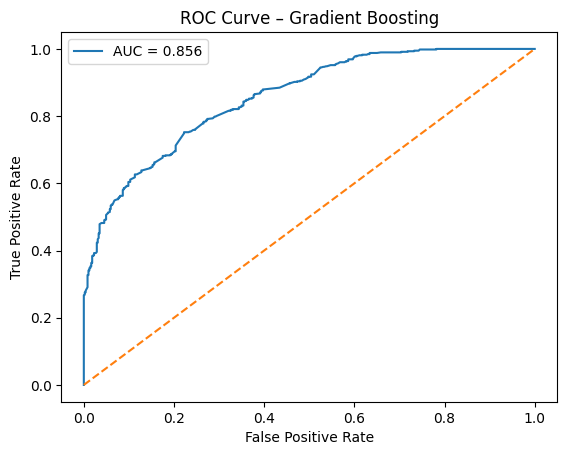

In [50]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_val, y_val_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Gradient Boosting")
plt.legend()
plt.show()


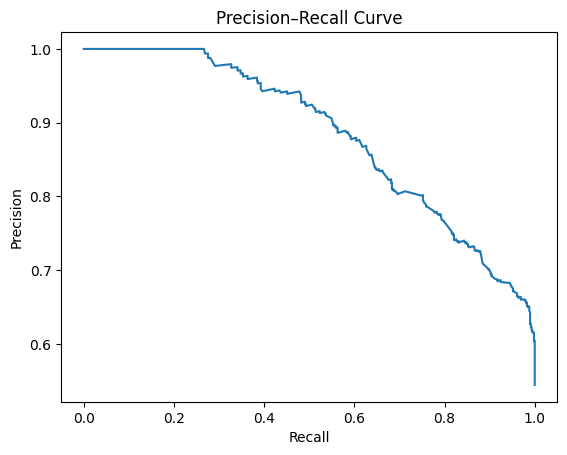

In [51]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_val, y_val_probs)

plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.show()


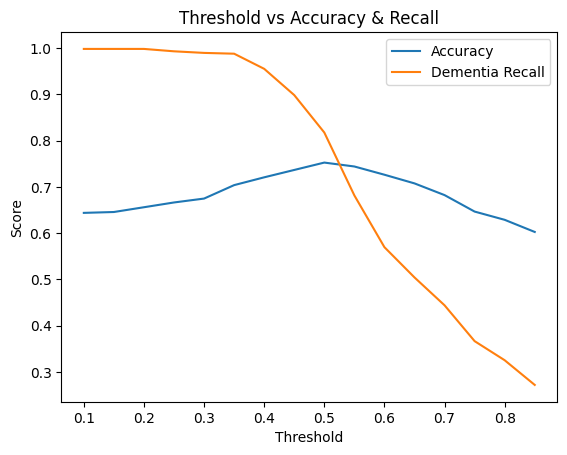

In [52]:
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

thresholds = np.arange(0.1, 0.9, 0.05)
acc_list, recall_list = [], []

for t in thresholds:
    preds = (y_val_probs >= t).astype(int)
    acc_list.append(accuracy_score(y_val, preds))
    recall_list.append(recall_score(y_val, preds))

plt.figure()
plt.plot(thresholds, acc_list, label="Accuracy")
plt.plot(thresholds, recall_list, label="Dementia Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold vs Accuracy & Recall")
plt.legend()
plt.show()


In [73]:
# TESTING

import joblib
import numpy as np

# Load saved model and scaler
model = joblib.load("dementia_gradient_boosting_model.pkl")
scaler = joblib.load("feature_scaler.pkl")

# Path to ANY random .cex file
cex_path = r"E:\A ALZEHIMER\Data\Control\002-1.mdrep(3).cex"   # change filename only

# Extract features (same function you used in training)
features = extract_features(cex_path)

# Reshape & scale
features = np.array(features).reshape(1, -1)
features_scaled = scaler.transform(features)

# Predict probability
prob = model.predict_proba(features_scaled)[0][1]

# Apply clinical threshold
threshold = 0.40
if prob < 0.40:
    interpretation = "Control (Low Risk)"
elif prob < 0.55:
    interpretation = "Borderline — Monitoring Recommended"
else:
    interpretation = "Dementia Risk"


print("🔍 Probability of Dementia:", round(prob, 3))
print("🧠 Prediction:", interpretation)


🔍 Probability of Dementia: 0.434
🧠 Prediction: Borderline — Monitoring Recommended
